# Import

In [1]:
import pandas as pd
import numpy as np

import geopandas as gpd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
from shapely.geometry import Point
from shapely.geometry import LineString
import json
from pyproj import CRS

pd.set_option('display.max_columns', None)
plt.rc('font', family='Malgun Gothic')


# Pre-Processing

In [58]:
# Data Load

df_num = pd.read_csv("./data/천안시_노선번호목록.csv")
df_stops = pd.read_csv("./data/천안시_노선별경유정류소목록.csv")
df_info = pd.read_csv("./data/천안시_노선정보항목.csv", sep='\t')

In [59]:

# 저상버스 노선 리스트 정의
lowfloor_routes = [
    9, 19, 51, 52, 55, 62, 63, 70, 71, 82, 83, 98, 590,
    113, 122, 130, 221, 229, 230, 231, 232, 234, 235, 236,
    237, 238, 251, 270, 310, 402, 510, 512, 520, 540, 614,
    620, 621, 650, 720, 730, 830, 840, 850, 860
]

# 노선 정보에 저상버스 여부 플래그 추가
df_routes = df_info.copy()
df_routes["저상버스"] = (~df_routes["노선번호"].isin(lowfloor_routes)).astype(int)


# 정류소-노선 매핑 데이터와 노선정보 조인
# (A) 정류소-노선 단위 (노선ID 유지)
df_bus_routes_raw = df_stops.merge(
    df_routes[["노선ID", "노선번호", "저상버스"]],
    on="노선ID",
    how="left"
)
df_bus_routes_raw.rename(columns={
    "정류소 X좌표": "X",
    "정류소 Y좌표": "Y"
}, inplace=True)

# (B) 정류소 단위 집계 (저상버스 비율)
df_bus_routes = (
    df_bus_routes_raw.groupby(["정류소ID", "정류소명", "X", "Y"])
    .agg({"저상버스": "mean"})
    .reset_index()
)

In [60]:
df_bus_routes

,정류소ID,정류소명,X,Y,저상버스
0,CAB214000030,평택역,127.087084,36.991534,0.0
1,CAB214000033,신평11통(유천3리),127.106688,36.973053,0.0
2,CAB214001064,신평9통(유천1리),127.115562,36.976733,0.0
3,CAB214001065,유천2리,127.111365,36.976805,0.0
4,CAB214001664,신평11동(유천3리),127.106823,36.972923,0.0
...,...,...,...,...,...
2457,CAB293064049,유천리,127.161675,36.688441,1.0
2458,CAB293064236,대곡리,127.166790,36.729839,1.0
2459,CAB293064387,소정리,127.158134,36.724503,1.0
2460,CAB293064405,동산산업,127.147259,36.710332,1.0


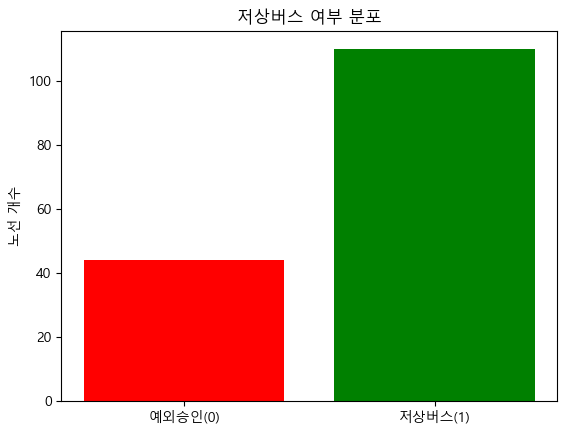

In [61]:
# 노선별 중복 제거 후 '저상버스' 컬럼 카운트
counts = df_routes.drop_duplicates(subset="노선번호")['저상버스'].value_counts().sort_index()

# 시각화
plt.bar(["예외승인(0)", "저상버스(1)"], counts, color=["red", "green"])
plt.title("저상버스 여부 분포")
plt.ylabel("노선 개수")
plt.show()

### 정류소 위치별 저상버스 여부

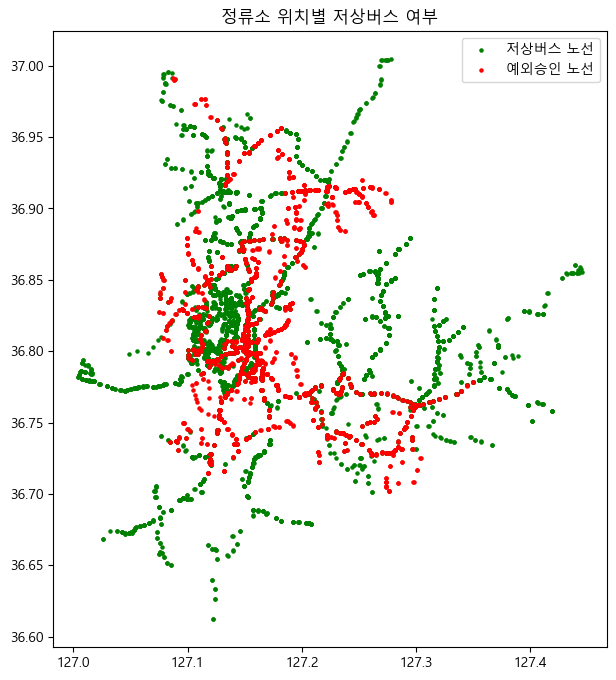

In [ ]:
# import geopandas as gpd
# import matplotlib.pyplot as plt

# # 정류소 데이터프레임 준비
# gdf_stops = gpd.GeoDataFrame(
#     df_stops,  # 정류소 데이터 (정류소 X좌표, 정류소 Y좌표 포함된 df)
#     geometry=gpd.points_from_xy(df_stops["정류소 X좌표"], df_stops["정류소 Y좌표"]),
#     crs="EPSG:4326"
# )

# # 정류소에 저상버스 여부 merge
# df_routes_slim = df_routes[["노선ID", "저상버스"]]
# df_bus_routes = df_stops.merge(df_routes_slim, on="노선ID", how="left")

# gdf_bus_routes = gpd.GeoDataFrame(
#     df_bus_routes,
#     geometry=gpd.points_from_xy(df_bus_routes["정류소 X좌표"], df_bus_routes["정류소 Y좌표"]),
#     crs="EPSG:4326"
# )

# # 시각화
# fig, ax = plt.subplots(figsize=(8, 8))
# gdf_bus_routes[gdf_bus_routes["저상버스"]==1].plot(ax=ax, markersize=5, color="green", label="저상버스 노선")
# gdf_bus_routes[gdf_bus_routes["저상버스"]==0].plot(ax=ax, markersize=5, color="red", label="예외승인 노선")
# plt.legend()
# plt.title("정류소 위치별 저상버스 여부")
# plt.show()

In [24]:
import plotly.express as px

# '저상버스 여부' 컬럼 생성 (숫자를 문자열로)
gdf_bus_routes['저상버스여부'] = gdf_bus_routes['저상버스'].map({1:'저상버스', 0:'예외승인'})

# hover에 표시할 정보 추가
gdf_bus_routes['hover_text'] = gdf_bus_routes.apply(
    lambda x: f"정류소: {x['정류소명']}<br>노선ID: {x['노선ID']}<br>저상버스 여부: {x['저상버스여부']}", axis=1
)

# 지도 시각화
fig = px.scatter_map(
    gdf_bus_routes,
    lat=gdf_bus_routes.geometry.y,
    lon=gdf_bus_routes.geometry.x,
    color='저상버스여부',  # 범주형 컬러
    hover_name='hover_text',
    zoom=11,
    height=700,
    title="정류소 위치별 저상버스 여부",
    color_discrete_map={'저상버스':'green', '예외승인':'red'}  # 범주별 색상 지정
)

fig.update_layout(map_style="open-street-map")
fig.update_layout(margin={"r":0,"t":50,"l":0,"b":0})

fig.show()


### 정류소 위치별 저상버스 여부

### plotly - 노선별 경유 정류소 목록 표시

In [25]:
df = pd.read_csv("./data/천안시_노선별경유정류소목록.csv")

df.columns

fig = px.scatter_map(
    df,
    lat="정류소 Y좌표",
    lon="정류소 X좌표",
    color="노선ID",
    hover_name="정류소명", # 마우스 오버 시 표시한 텍스트
    # hover_data={},
    # text="text",
    zoom=11,
    height=650,
    );
 # carto-positron : 무료, 지도 배경 스타일 지정
fig.update_layout(map_style="carto-positron", margin={"r":0,"t":0,"l":0,"b":0})
fig.show();

In [26]:
df = pd.read_csv("./data/천안시_노선별경유정류소목록.csv")

df.columns

fig = px.scatter_map(
    df,
    lat="정류소 Y좌표",
    lon="정류소 X좌표",
    color="노선ID",
    hover_name="정류소명", # 마우스 오버 시 표시한 텍스트
    # hover_data={},
    # text="text",
    zoom=11,
    height=650,
    );

fig.update_layout(map_style="open-street-map", margin={"r":0,"t":0,"l":0,"b":0})
fig.show();

### shp 파일로 Choropleth Mapbox 생성

In [27]:
### shp 파일
# .shp 불러오기 → 좌표계 변환 → .geojson 저장
# CSV 불러오기 → 자치구별 데이터 집계
# GeoJSON과 CSV의 키값 맞추기
# Plotly로 색깔 입힌 지도(Choropleth Mapbox) 생성

# 1. 읍면동 경계 shp 파일 불러오기, 좌표계 변환
gdf = gpd.read_file("./data/map_data/emd.shp", encoding="cp949")
print("원본 좌표계:", gdf.crs)

gdf.crs = "EPSG:5179"  # 원본 좌표계 지정 (예: UTM-K)
gdf = gdf.to_crs(epsg=4326)  # WGS84 위경도로 변환

# 2. 정류소 CSV 불러오기
df = pd.read_csv("./data/천안시_노선별경유정류소목록.csv")

# 3. 정류소 DataFrame에 위도,경도 기준 Point geometry 생성 (경도=X, 위도=Y)
geometry = [Point(xy) for xy in zip(df['정류소 X좌표'], df['정류소 Y좌표'])]
gdf_stops = gpd.GeoDataFrame(df, geometry=geometry, crs='EPSG:4326')

# 4. 공간 조인 (정류소 포인트가 포함된 읍면동 폴리곤 가져오기)
gdf_joined = gpd.sjoin(gdf_stops, gdf, how='left', predicate='within')

# 5. 읍면동명 컬럼명 확인 (예: 'EMD_KOR_NM')와 필요한 컬럼 추출
print(gdf_joined.columns)
# 일반적으로 읍면동 명 컬럼이 'EMD_KOR_NM'일 가능성 높음

# 6. 읍면동별 정류소 수 집계
agg_df = gdf_joined.groupby('EMD_KOR_NM').size().reset_index(name='정류소수')
print(agg_df.head())

원본 좌표계: None
Index(['정류소 Y좌표', '정류소 X좌표', '정류소ID', '정류소명', '정류소번호', '정류소순번', '노선ID',
       'geometry', 'index_right', 'EMD_CD', 'EMD_ENG_NM', 'EMD_KOR_NM'],
      dtype='object')
  EMD_KOR_NM  정류소수
0         계동     4
1        광덕면   176
2        구룡동    20
3        구성동   230
4        군문동     4


In [28]:
# 7. GeoJSON 파일로 저장 (Plotly용)
# gdf.to_file("./data/map_data/mapfile.geojson", driver="GeoJSON")

with open('./data/map_data/mapfile.geojson', encoding='utf-8') as f:
    geojson_data = json.load(f)

# 8. Plotly Choropleth Mapbox 시각화
fig = px.choropleth_map(
    agg_df,
    geojson=geojson_data,
    locations='EMD_KOR_NM',
    featureidkey='properties.EMD_KOR_NM',
    color='정류소수',
    color_continuous_scale='Viridis',
    map_style='carto-positron',
    center={'lat': 36.8, 'lon': 127.1},  # 천안시 중심 좌표 설정
    zoom=10,
    opacity=0.6,
    labels={'정류소수': '정류소 개수'},
    title='읍면동별 정류소 개수'
)

# open-street-map
# carto-positron

fig.update_layout(margin={"r":0,"t":30,"l":0,"b":0})
fig.show()

In [29]:
# 7. GeoJSON 파일로 저장 (Plotly용)
# gdf.to_file("./data/map_data/mapfile.geojson", driver="GeoJSON")

with open('./data/map_data/mapfile.geojson', encoding='utf-8') as f:
    geojson_data = json.load(f)

# 8. Plotly Choropleth Mapbox 시각화
fig = px.choropleth_map(
    agg_df,
    geojson=geojson_data,
    locations='EMD_KOR_NM',
    featureidkey='properties.EMD_KOR_NM',
    color='정류소수',
    color_continuous_scale='Viridis',
    map_style='open-street-map',
    center={'lat': 36.8, 'lon': 127.1},  # 천안시 중심 좌표 설정
    zoom=10,
    opacity=0.6,
    labels={'정류소수': '정류소 개수'},
    title='읍면동별 정류소 개수'
)

# open-street-map
# carto-positron

fig.update_layout(margin={"r":0,"t":30,"l":0,"b":0})
fig.show()

### 노선별 line string 시각화

In [17]:
# 1. 정류소 데이터 불러오기
df = pd.read_csv('./data_HWJ/천안시_노선별경유정류소목록.csv')

# 2. 노선별 정류소를 순서대로 정렬
df_sorted = df.sort_values(by=['노선ID', '정류소순번'])

# 3. 노선별 LineString 생성 함수
def create_linestring(group):
    points = list(zip(group['정류소 X좌표'], group['정류소 Y좌표']))
    return LineString(points)

# 4. 노선별 LineString GeoDataFrame 생성
lines = df_sorted.groupby('노선ID').apply(create_linestring).reset_index()
lines.columns = ['노선ID', 'geometry']
gdf_lines = gpd.GeoDataFrame(lines, geometry='geometry', crs='EPSG:4326')

# 5. Plotly로 시각화
fig = go.Figure()

colors = px.colors.qualitative.Dark24  # 색상 팔레트

for i, (route_id, row) in enumerate(gdf_lines.iterrows()):
    x, y = row.geometry.xy
    lon = list(x)  # array -> list 변환
    lat = list(y)
    fig.add_trace(go.Scattermapbox(
        lon=lon,
        lat=lat,
        mode='lines+markers',
        name=route_id,
        line=dict(width=1, color=colors[i % len(colors)]),
        marker=dict(size=5)
    ))

fig.update_layout(
    mapbox_style='carto-positron',
    mapbox_center={"lat": 36.8, "lon": 127.1},  # 천안시 중심 좌표
    mapbox_zoom=10,
    margin={"r":0,"t":0,"l":0,"b":0},
    legend_title_text='노선ID별',
    title='노선별 정류소 시각화'
    
)

fig.show()


NameError: name 'LineString' is not defined

In [16]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import plotly.express as px

# --------------------
# 1. 데이터 불러오기
# --------------------
stops_df = pd.read_csv("./data_HWJ/천안시_노선별경유정류소목록.csv")
facilities_df = pd.read_csv("./data_HWJ/장애인_재활시설.csv")
gdf_region = gpd.read_file("./data_HWJ/map_data/mapfile.geojson")

# --------------------
# 2. GeoDataFrame 변환 & 좌표계 통일
# --------------------
# 정류소
gdf_stops = gpd.GeoDataFrame(
    stops_df,
    geometry=gpd.points_from_xy(stops_df["정류소 X좌표"], stops_df["정류소 Y좌표"]),
    crs="EPSG:4326"
).to_crs(epsg=5179)

# 복지시설
gdf_facilities = gpd.GeoDataFrame(
    facilities_df,
    geometry=gpd.points_from_xy(facilities_df["경도"], facilities_df["위도"]),
    crs="EPSG:4326"
).to_crs(epsg=5179)

# 읍면동 경계
if gdf_region.crs is None:
    gdf_region = gdf_region.set_crs(epsg=4326)
gdf_region = gdf_region.to_crs(epsg=5179)

# --------------------
# 3. 정류소 500m Buffer & 시설 교차 여부
# --------------------
gdf_stops["geometry_buffer"] = gdf_stops.buffer(500)
gdf_stops["복지시설500m이내"] = gdf_stops["geometry_buffer"].apply(
    lambda buf: gdf_facilities.intersects(buf).any()
).astype(int)

# --------------------
# 4. 읍면동 Spatial Join
# --------------------
if "index_right" in gdf_stops.columns:
    gdf_stops = gdf_stops.drop(columns="index_right")

gdf_stops = gpd.sjoin(
    gdf_stops,
    gdf_region[["EMD_KOR_NM", "geometry"]],
    how="left",
    predicate="intersects"
)

gdf_stops = gdf_stops.loc[:, ~gdf_stops.columns.duplicated()]

# --------------------
# 5. 읍면동별 집계
# --------------------
result = (
    gdf_stops.groupby("EMD_KOR_NM")
    .agg(
        총정류소수=("정류소명", "count"),
        복지시설500m이내=("복지시설500m이내", "sum")
    )
    .reset_index()
)
result["비율(%)"] = (result["복지시설500m이내"] / result["총정류소수"] * 100).round(1)
result["비율(%)"] = result["비율(%)"].fillna(0)

# --------------------
# 6. Choropleth 시각화 (Mapbox 없이)
# --------------------
# 지도용 좌표계: WGS84(EPSG:4326)
gdf_region_plot = gdf_region.to_crs(epsg=4326)
gdf_region_plot = gdf_region_plot.merge(result, on="EMD_KOR_NM", how="left")

fig = px.choropleth(
    gdf_region_plot,
    geojson=gdf_region_plot.__geo_interface__,
    locations="EMD_KOR_NM",
    featureidkey="properties.EMD_KOR_NM",
    color="비율(%)",
    hover_data=["EMD_KOR_NM", "총정류소수", "복지시설500m이내", "비율(%)"],
    color_continuous_scale="Blues",
    labels={"비율(%)": "500m 이내 복지시설 비율"}
)

fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(
    title="천안시 읍면동별 정류소 500m 이내 복지시설 접근성",
    margin={"r":0,"t":30,"l":0,"b":0}
)

fig.show()

In [5]:
# --------------------
# 1. 데이터 불러오기
# --------------------
stops_df = pd.read_csv("./data_HWJ/천안시_노선별경유정류소목록.csv")
facilities_df = pd.read_csv("./data_HWJ/장애인_재활시설.csv")
gdf_region = gpd.read_file("./data_HWJ/map_data/mapfile.geojson")

# --------------------
# 2. GeoDataFrame 변환 & 좌표계 통일
# --------------------
# 정류소
gdf_stops = gpd.GeoDataFrame(
    stops_df,
    geometry=gpd.points_from_xy(stops_df["정류소 X좌표"], stops_df["정류소 Y좌표"]),
    crs="EPSG:4326"
).to_crs(epsg=5179)

# 복지시설
gdf_facilities = gpd.GeoDataFrame(
    facilities_df,
    geometry=gpd.points_from_xy(facilities_df["경도"], facilities_df["위도"]),
    crs="EPSG:4326"
).to_crs(epsg=5179)

# 읍면동 경계
if gdf_region.crs is None:
    gdf_region = gdf_region.set_crs(epsg=4326)
gdf_region = gdf_region.to_crs(epsg=5179)

# --------------------
# 3. 정류소 500m Buffer & 시설 교차 여부
# --------------------
gdf_stops["geometry_buffer"] = gdf_stops.buffer(500)
gdf_stops["복지시설500m이내"] = gdf_stops["geometry_buffer"].apply(
    lambda buf: gdf_facilities.intersects(buf).any()
).astype(int)

# --------------------
# 4. 읍면동 Spatial Join
# --------------------
if "index_right" in gdf_stops.columns:
    gdf_stops = gdf_stops.drop(columns="index_right")

gdf_stops = gpd.sjoin(
    gdf_stops,
    gdf_region[["EMD_KOR_NM", "geometry"]],
    how="left",
    predicate="intersects"
)

gdf_stops = gdf_stops.loc[:, ~gdf_stops.columns.duplicated()]

# --------------------
# 5. 읍면동별 집계
# --------------------
result = (
    gdf_stops.groupby("EMD_KOR_NM")
    .agg(
        총정류소수=("정류소명", "count"),
        복지시설500m이내=("복지시설500m이내", "sum")
    )
    .reset_index()
)
result["비율(%)"] = (result["복지시설500m이내"] / result["총정류소수"] * 100).round(1)
result["비율(%)"] = result["비율(%)"].fillna(0)

# --------------------
# 6. Choropleth 시각화 (Mapbox 없이)
# --------------------
# 지도용 좌표계: WGS84(EPSG:4326)
gdf_region_plot = gdf_region.to_crs(epsg=4326)
gdf_region_plot = gdf_region_plot.merge(result, on="EMD_KOR_NM", how="left")

fig = px.choropleth_map(
    gdf_region_plot,
    geojson=gdf_region_plot.__geo_interface__,
    locations="EMD_KOR_NM",
    featureidkey="properties.EMD_KOR_NM",
    color="비율(%)",
    hover_data=["EMD_KOR_NM", "총정류소수", "복지시설500m이내", "비율(%)"],
    color_continuous_scale="Blues",
    labels={"비율(%)": "500m 이내 복지시설 비율"}
)

fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(
    title="천안시 읍면동별 정류소 500m 이내 복지시설 접근성",
    margin={"r":0,"t":30,"l":0,"b":0}
)

fig.show()

In [6]:
gdf_region

,EMD_CD,EMD_ENG_NM,EMD_KOR_NM,geometry
0,44131101,Daeheung-dong,대흥동,"POLYGON ((968747.454 1868265.138, 968746.957 1..."
1,44131102,Seonghwang-dong,성황동,"POLYGON ((968773.015 1868252.121, 968773.015 1..."
2,44131103,Munhwa-dong,문화동,"POLYGON ((968773.015 1868252.121, 968773.015 1..."
3,44131104,Sajik-dong,사직동,"POLYGON ((968796.642 1867370.378, 968799.161 1..."
4,44131105,Yeongseong-dong,영성동,"POLYGON ((969017.757 1867414.43, 969018.178 18..."
5,44131106,Oryong-dong,오룡동,"POLYGON ((968897.148 1867648.549, 968927.717 1..."
6,44131107,Wonseong-dong,원성동,"POLYGON ((969122.74 1867979.613, 969201.795 18..."
7,44131108,Guseong-dong,구성동,"POLYGON ((971890.053 1867155.482, 971891.061 1..."
8,44131109,Cheongsu-dong,청수동,"POLYGON ((969717.441 1865982.846, 969717.051 1..."
9,44131110,Samnyong-dong,삼룡동,"POLYGON ((971948.392 1866100.931, 972023.599 1..."


# 본론 시각화

1. 복지시설까지의 거리
2. 저상버스 적용유무
3. 지나가는 노선이 몇개인지
4. 해당 지역의 노인, 장애인 인구 밀도

1. 격자 단위 생성 → 분석 단위 정의
2. 거리 계산 → 격자 중심점 ↔ 복지시설
    - 400m → 단거리 접근 가능
    - 800m → 보통 접근 가능
    - 800m < → 접근성 낮음
3. 저상버스 적용 여부 → 실질적 접근성 평가
4. 노선 수 확인 → 서비스 수준 반영
    - 각 격자에서 복지시설까지 정류소·노선 연결망 분석
    - 노선 수 많을수록 선택권·서비스 수준 ↑
5. 인구밀도 반영 → 수요 기반 가중치
    - 단위 격자별 고령자/장애인 인구 비율을 행정통계에서 배분
6. 접근성 점수화 → 종합 지표 산출 (거리, 저상버스, 노선 수, 수요)
7. 취약 격자 식별 → 지도 시각화
8. 정책 제안 → 노선 신설 / 셔틀버스 등

## 1. create_grid
격자 단위 생성 → 분석 단위 정의

In [7]:
import geopandas as gpd
from shapely.geometry import box

def create_grid(gdf_city, grid_size=500):
    # 1. 미터 단위 투영 CRS로 변환
    gdf_city_proj = gdf_city.to_crs(epsg=5179)  # 한국 TM 중앙 좌표계

    # 2. 투영 좌표계에서 bounds 확인
    xmin, ymin, xmax, ymax = gdf_city_proj.total_bounds

    # 3. 전체 그리드 생성
    grid_cells = []
    for x0 in range(int(xmin), int(xmax), grid_size):
        for y0 in range(int(ymin), int(ymax), grid_size):
            grid_cells.append(box(x0, y0, x0+grid_size, y0+grid_size))

    gdf_grid = gpd.GeoDataFrame({'geometry': grid_cells}, crs=gdf_city_proj.crs)

    # 4. 천안시 경계와 겹치는 셀만 남기기
    gdf_grid = gpd.overlay(gdf_grid, gdf_city_proj, how='intersection')

    return gdf_grid

## 2. calculate_distance
거리 계산 → 격자 중심점 ↔ 복지시설

In [8]:
from shapely.geometry import Point
import geopandas as gpd

# 셀 중심점 계산해서 새로운 컬럼으로 추가
def add_grid_centroid(gdf_grid):
    gdf_grid['centroid'] = gdf_grid.geometry.centroid
    return gdf_grid

def compute_nearest_facility(gdf_grid, gdf_facility):
    """
    각 격자 중심점(centroid)에서 최근접 복지시설까지의 거리 계산 (미터 단위)
    gdf_grid: 격자 GeoDataFrame (centroid 컬럼 필요)
    gdf_facility: 시설 GeoDataFrame (geometry Point, EPSG:4326)
    """
    
    gdf_facility = gpd.GeoDataFrame(
    gdf_facility,
    geometry=gpd.points_from_xy( gdf_facility['경도'],gdf_facility['위도']),
    crs="EPSG:4326"  # 경위도 좌표계
    )

    # 1. CRS 투영 (미터 단위)
    gdf_grid_proj = gdf_grid.to_crs(epsg=5179)
    gdf_facility_proj = gdf_facility.to_crs(epsg=5179)

    # 2. 거리 계산
    distances = []
    for c in gdf_grid_proj['centroid']:
        dist = gdf_facility_proj.distance(c).min()
        distances.append(dist)

    # 3. 결과 컬럼 추가
    gdf_grid_proj['min_distance_to_facility'] = distances

    # 4. 원래 CRS(EPSG:4326)로 변환
    gdf_grid_result = gdf_grid_proj.to_crs(epsg=4326)

    return gdf_grid_result

In [9]:
# def compute_lowfloor_score(gdf_grid, df_bus_routes):
#     """
#     gdf_grid: 격자 GeoDataFrame (centroid 있음)
#     df_bus_routes: 노선별 정보 (lowfloor 여부, 노선 경유 좌표)
#     """
#     # 임시 컬럼 초기화
#     gdf_grid['lowfloor_score'] = 0.0

#     # 각 격자 centroid 기준으로 계산
#     for idx, row in gdf_grid.iterrows():
#         centroid = row['centroid']

#         # centroid와 가까운 정류소 찾기 (예: 500m 반경)
#         nearby_stops = df_bus_routes[
#             (np.abs(df_bus_routes['X'] - centroid.x) <= 0.005) & 
#             (np.abs(df_bus_routes['Y'] - centroid.y) <= 0.005)
#         ]

#         if len(nearby_stops) > 0:
#             lowfloor_ratio = nearby_stops['저상버스'].mean()  # 0~1
#         else:
#             lowfloor_ratio = 0

#         gdf_grid.at[idx, 'lowfloor_score'] = lowfloor_ratio

#     return gdf_grid

In [10]:
def compute_lowfloor_score(gdf_grid, df_bus_routes, buffer_m=500):
    """
    gdf_grid: 격자 GeoDataFrame (centroid 있음, EPSG:4326)
    df_bus_routes: pandas DataFrame (X=경도, Y=위도, 저상버스 여부)
    buffer_m: 탐색 반경 (m)
    """
    # 1. df_bus_routes → GeoDataFrame 변환
    gdf_routes = gpd.GeoDataFrame(
        df_bus_routes,
        geometry=gpd.points_from_xy(df_bus_routes['X'], df_bus_routes['Y']),
        crs="EPSG:4326"
    )

    # 2. 미터 단위 좌표계로 변환
    gdf_grid_proj = gdf_grid.to_crs(epsg=5179)
    gdf_routes_proj = gdf_routes.to_crs(epsg=5179)

    # 3. centroid 확보
    if 'centroid' not in gdf_grid_proj.columns:
        gdf_grid_proj['centroid'] = gdf_grid_proj.geometry.centroid

    # 4. 점수 계산
    scores = []
    for c in gdf_grid_proj['centroid']:
        buffer = c.buffer(buffer_m)
        nearby_stops = gdf_routes_proj[gdf_routes_proj.geometry.within(buffer)]

        if len(nearby_stops) > 0:
            lowfloor_ratio = nearby_stops['저상버스'].mean()
        else:
            lowfloor_ratio = 0

        scores.append(lowfloor_ratio)

    gdf_grid_proj['lowfloor_score'] = scores

    # 5. 원래 CRS로 복원
    return gdf_grid_proj.to_crs(epsg=4326)

In [11]:
def compute_num_routes_score(gdf_grid, df_bus_routes, buffer_m=500):
    """
    각 격자별 경유 노선 수 정규화 (0~1)
    gdf_grid: 격자 GeoDataFrame (EPSG:4326)
    df_bus_routes: 정류소 + 노선 정보 DataFrame (X, Y, 노선ID 포함)
    buffer_m: 탐색 반경 (m)
    """
    # 정류소를 GeoDataFrame으로 변환
    gdf_stops = gpd.GeoDataFrame(
        df_bus_routes,
        geometry=gpd.points_from_xy(df_bus_routes['X'], df_bus_routes['Y']),
        crs="EPSG:4326"
    )
    
    # 투영 (미터 단위 좌표계)
    gdf_grid_proj = gdf_grid.to_crs(epsg=5179)
    gdf_stops_proj = gdf_stops.to_crs(epsg=5179)

    # 최대 노선 수 (정규화용)
    max_routes = df_bus_routes['노선ID'].nunique()

    scores = []
    for centroid in gdf_grid_proj['centroid']:
        # 반경 buffer 내 정류소 추출
        nearby_stops = gdf_stops_proj[gdf_stops_proj.geometry.within(centroid.buffer(buffer_m))]
        
        if len(nearby_stops) > 0:
            n_routes = nearby_stops['노선ID'].nunique()
            scores.append(n_routes / max_routes)
        else:
            scores.append(0.0)

    gdf_grid_proj['num_routes_score'] = scores

    # 원래 좌표계로 되돌리기
    gdf_grid_result = gdf_grid_proj.to_crs(epsg=4326)

    return gdf_grid_result

# def compute_population_score(gdf_grid, gdf_population):
#     """
#     gdf_population: 읍면동 또는 격자 단위 인구 GeoDataFrame
#     """
#     gdf_grid['population_score'] = 0.0
#     max_pop = gdf_population['population'].max()

#     for idx, row in gdf_grid.iterrows():
#         centroid = row['centroid']
#         # 격자 안 인구 합
#         pop_sum = gdf_population[gdf_population.geometry.within(row['geometry'])]['population'].sum()
#         gdf_grid.at[idx, 'population_score'] = pop_sum / max_pop

#     return gdf_grid

## 3. analyze_accessibility

In [12]:
"""
analyze_accessibility.py
------------------------
격자별 접근성 점수 계산.
- 거리 점수
- 저상버스 점수
- 노선 수 점수
- 고령/장애인 인구 점수
"""

def compute_accessibility_score(df_grid):
    # 거리 점수 예시: 0~1
    df_grid['distance_score'] = df_grid['min_distance_to_facility'].apply(
        lambda x: 1 if x <= 400 else (0.5 if x <= 800 else 0)
        
    )
    

    
    # 저상버스, 노선, 인구 점수는 0~1로 정규화 후 가중치 합산
    df_grid['accessibility_score'] = (
        0.33*df_grid['distance_score'] +
        0.33*df_grid['lowfloor_score'] +
        0.33*df_grid['num_routes_score']
        # 0.1*df_grid['population_score']
    )
    return df_grid

## 4. visualize_map

In [13]:
import pydeck as pdk

def visualize_grid_pydeck(gdf_grid):
    layer = pdk.Layer(
        "ColumnLayer",
        gdf_grid,
        get_position=["lon", "lat"],
        get_elevation="accessibility_score*500",  # 접근성 점수 반영
        radius=50,
        get_fill_color="[255*(1-accessibility_score), 255*accessibility_score, 0]",
        pickable=True,
        auto_highlight=True,
    )
    view_state = pdk.ViewState(latitude=36.8, longitude=127.0, zoom=12)
    r = pdk.Deck(layers=[layer], initial_view_state=view_state)
    return r

In [14]:
import plotly.express as px

def plot_accessibility_plotly(gdf_grid, score_column='accessibility_score'):
    gdf_grid = gdf_grid.to_crs(epsg=4326)  # WGS84 좌표계 필요

    # Plotly Choropleth
    fig = px.choropleth_map(
        gdf_grid,
        geojson=gdf_grid.geometry,
        locations=gdf_grid.index,
        color=score_column,
        color_continuous_scale="YlOrRd",
        map_style="carto-positron",
        zoom=11,
        center={"lat": gdf_grid.geometry.centroid.y.mean(),
                "lon": gdf_grid.geometry.centroid.x.mean()},
        opacity=0.7,
        hover_data=[score_column]
    )

    fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0},
                      width=1200,
                      height=800)
    return fig

In [15]:
import geopandas as gpd
# from scripts.create_grid import create_grid
# from scripts.calculate_distance import add_grid_centroid, compute_nearest_facility
# from scripts.analyze_accessibility import compute_accessibility_score
# from scripts.visualize_map import plot_accessibility_map

# 데이터 불러오기
gdf_city = gpd.read_file('data/map_data/mapfile.geojson')
gdf_facility = gpd.read_file('data/장애인_재활시설.csv')

# 격자 생성
gdf_grid = create_grid(gdf_city)
gdf_grid = add_grid_centroid(gdf_grid)

DataSourceError: data/map_data/mapfile.geojson: No such file or directory

In [ ]:
# 거리 계산
gdf_grid = compute_nearest_facility(gdf_grid, gdf_facility)

In [ ]:
# 저상버스 점수
gdf_grid = compute_lowfloor_score(gdf_grid, df_bus_routes)

# 노선 수 점수
gdf_grid = compute_num_routes_score(gdf_grid, df_bus_routes_raw)

# 3. 인구 점수
# gdf_grid = compute_population_score(gdf_grid, gdf_population)


In [ ]:
df_bus_routes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2462 entries, 0 to 2461
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   정류소ID   2462 non-null   object 
 1   정류소명    2462 non-null   object 
 2   X       2462 non-null   float64
 3   Y       2462 non-null   float64
 4   저상버스    2462 non-null   float64
dtypes: float64(3), object(2)
memory usage: 96.3+ KB


In [ ]:
# 접근성 점수 계산 (lowfloor_score, num_routes_score, population_score 전처리 후)
gdf_grid = compute_accessibility_score(gdf_grid)

In [ ]:
# 지도 시각화
map_obj = plot_accessibility_plotly(gdf_grid)
map_obj

C:\Users\USER\AppData\Local\Temp\ipykernel_19800\2685971092.py:15: UserWarning:

Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.


C:\Users\USER\AppData\Local\Temp\ipykernel_19800\2685971092.py:16: UserWarning:

Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.




In [ ]:
import osmnx as ox

# 천안시 중심 좌표
place = "Cheonan, South Korea"
roads = ox.graph_from_place(place, network_type='drive')  # 도로망
gdf_roads = ox.graph_to_gdfs(roads, nodes=False, edges=True)
gdf_roads.to_file("cheonan_roads.geojson", driver="GeoJSON")

: 

Skipping field highway: unsupported OGR type: 5
Skipping field name: unsupported OGR type: 5
Skipping field maxspeed: unsupported OGR type: 5
Skipping field ref: unsupported OGR type: 5
Skipping field lanes: unsupported OGR type: 5


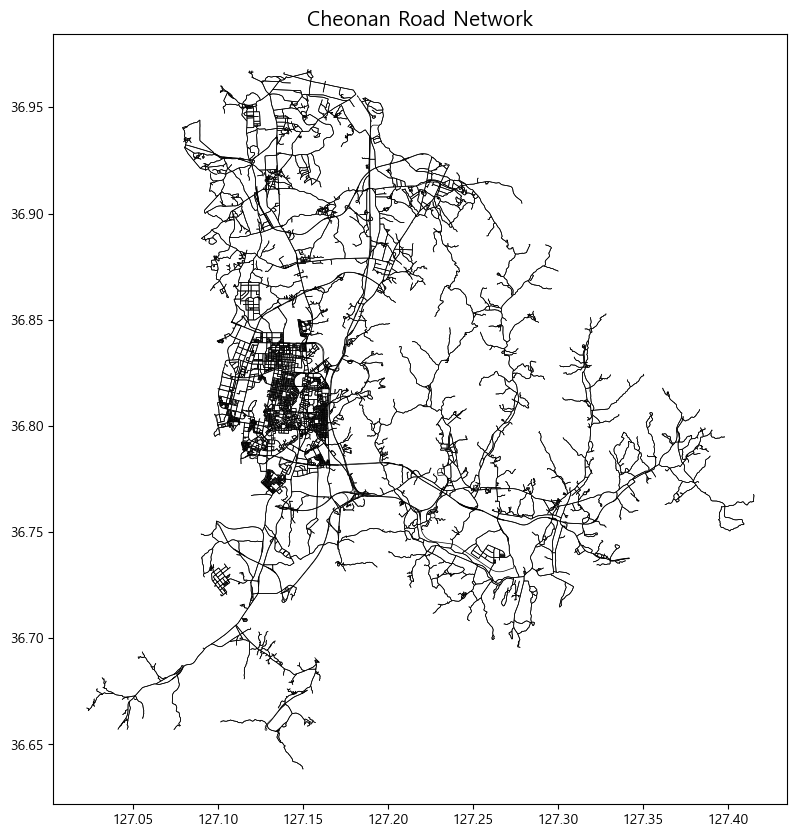

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

# 도로망 불러오기
gdf_roads = gpd.read_file("cheonan_roads.geojson")

# 시각화
fig, ax = plt.subplots(figsize=(10,10))
gdf_roads.plot(ax=ax, linewidth=0.5, color="black")
plt.title("Cheonan Road Network", fontsize=15)
plt.show()

In [ ]:
gdf_roads.head()

,u,v,key,osmid,oneway,reversed,length,bridge,access,tunnel,junction,geometry
0,414911099,4662971720,0,507050606,True,False,89.396786,None,None,None,None,"LINESTRING (127.12906 36.79163, 127.12908 36.7..."
1,414911099,4970343490,0,471347721,False,True,64.368427,None,None,None,None,"LINESTRING (127.12906 36.79163, 127.12916 36.7..."
2,414911117,5226691540,0,"[ 384791072, 384791070, 384791071 ]",False,False,115.223420,yes,None,None,None,"LINESTRING (127.31576 36.82771, 127.31507 36.8..."
3,414911117,3881466286,0,664122009,False,False,165.610943,None,None,None,None,"LINESTRING (127.31576 36.82771, 127.31576 36.8..."
4,414911117,3879825528,0,664122009,False,True,265.092537,None,None,None,None,"LINESTRING (127.31576 36.82771, 127.31579 36.8..."


In [ ]:
import geopandas as gpd
import plotly.graph_objects as go

# 도로망 불러오기
gdf_roads = gpd.read_file("cheonan_roads.geojson")

# ✅ 도로 일부만 샘플링
sample_gdf = gdf_roads.sample(100, random_state=42)

road_traces = []
for _, row in sample_gdf.iterrows():
    geom = row.geometry
    if geom.geom_type == "LineString":
        x, y = geom.xy
        road_traces.append(go.Scattermapbox(
            lon=list(x),
            lat=list(y),
            mode="lines",
            line=dict(width=1, color="black"),
            opacity=0.5,
            showlegend=False
        ))
    elif geom.geom_type == "MultiLineString":
        for line in geom:
            x, y = line.xy
            road_traces.append(go.Scattermapbox(
                lon=list(x),
                lat=list(y),
                mode="lines",
                line=dict(width=1, color="black"),
                opacity=0.5,
                showlegend=False
            ))

fig = go.Figure(road_traces)
fig.update_layout(
    mapbox=dict(
        style="open-street-map",
        center={"lat": 36.815, "lon": 127.113}, 
        zoom=11
    ),
    margin={"r":0,"t":0,"l":0,"b":0}
)

fig.show()

Skipping field highway: unsupported OGR type: 5
Skipping field name: unsupported OGR type: 5
Skipping field maxspeed: unsupported OGR type: 5
Skipping field ref: unsupported OGR type: 5
Skipping field lanes: unsupported OGR type: 5
C:\Users\USER\AppData\Local\Temp\ipykernel_19196\3703148861.py:15: DeprecationWarning:

*scattermapbox* is deprecated! Use *scattermap* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/



In [ ]:
import geopandas as gpd
import plotly.graph_objects as go

# 도로망 불러오기
gdf_roads = gpd.read_file("cheonan_roads.geojson")

# ✅ 도로 일부만 샘플링
sample_gdf = gdf_roads.sample(200, random_state=42)

road_traces = []
for _, row in sample_gdf.iterrows():
    geom = row.geometry
    if geom.geom_type == "LineString":
        x, y = geom.xy
        road_traces.append(go.Scattermap(
            lon=list(x),
            lat=list(y),
            mode="lines",
            line=dict(width=10, color="blue"),
            opacity=0.5,
            showlegend=False
        ))
    elif geom.geom_type == "MultiLineString":
        for line in geom:
            x, y = line.xy
            road_traces.append(go.Scattermap(
                lon=list(x),
                lat=list(y),
                mode="lines",
                line=dict(width=10, color="blue"),
                opacity=0.5,
                showlegend=False
            ))

fig = go.Figure(road_traces)
fig.update_layout(
    map=dict(
        style="open-street-map",
        center={"lat": 36.815, "lon": 127.113}, 
        zoom=11
    ),
    margin={"r":0,"t":0,"l":0,"b":0}
)

fig.show()

Skipping field highway: unsupported OGR type: 5
Skipping field name: unsupported OGR type: 5
Skipping field maxspeed: unsupported OGR type: 5
Skipping field ref: unsupported OGR type: 5
Skipping field lanes: unsupported OGR type: 5


In [ ]:
import geopandas as gpd
import plotly.graph_objects as go
from shapely.geometry import LineString, MultiLineString

# ------------------------
# 1. 도로망 불러오기
# ------------------------
gdf_roads = gpd.read_file("cheonan_roads.geojson")

# ------------------------
# 3. 도로 단순화
# ------------------------
tolerance = 0.005  # 좌표 단위를 크게 하여 점 수 줄임
gdf_roads['geometry'] = gdf_roads.geometry.simplify(tolerance, preserve_topology=True)

# ------------------------
# 4. Plotly용 trace 생성
# ------------------------
road_traces = []

for _, row in gdf_roads.iterrows():
    geom = row.geometry
    if geom.geom_type == "LineString":
        x, y = geom.xy
        x, y = x[::10], y[::10]  # 좌표 간격 늘리기
        road_traces.append(go.Scattermapbox(
            lon=list(x),
            lat=list(y),
            mode="lines",
            line=dict(width=1, color="black"),
            opacity=0.5,
            showlegend=False
        ))
    elif geom.geom_type == "MultiLineString":
        for line in geom:
            x, y = line.xy
            x, y = x[::10], y[::10]
            road_traces.append(go.Scattermapbox(
                lon=list(x),
                lat=list(y),
                mode="lines",
                line=dict(width=1, color="black"),
                opacity=0.5,
                showlegend=False
            ))

# ------------------------
# 5. 지도 그리기
# ------------------------
fig = go.Figure(road_traces)
fig.update_layout(
    mapbox=dict(
        style="open-street-map",
        center={"lat": 36.815, "lon": 127.113}, 
        zoom=11
    ),
    margin={"r":0,"t":0,"l":0,"b":0},
    width=1200,
    height=800
)

fig.show()

Skipping field highway: unsupported OGR type: 5
Skipping field name: unsupported OGR type: 5
Skipping field maxspeed: unsupported OGR type: 5
Skipping field ref: unsupported OGR type: 5
Skipping field lanes: unsupported OGR type: 5
C:\Users\USER\AppData\Local\Temp\ipykernel_19716\2393781086.py:26: DeprecationWarning: *scattermapbox* is deprecated! Use *scattermap* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/
  road_traces.append(go.Scattermapbox(
